Starting synthetic stock data generation...
Generating data for TECH_A...
Generating data for TECH_B...
Generating data for FINANCE_A...
Generating data for HEALTH_A...
Generating data for ENERGY_A...
Generating data for CONSUMER_A...
Generating data for TECH_C...
Generating data for FINANCE_B...
Dataset generation completed!
Dataset shape: (9594, 12)
Date range: 2020-01-01 00:00:00 to 2024-01-31 00:00:00
Companies generated: ['MARKET_INDEX', 'TECH_A', 'TECH_B', 'FINANCE_A', 'HEALTH_A', 'ENERGY_A', 'CONSUMER_A', 'TECH_C', 'FINANCE_B']
Sectors: ['Index', 'tech_growth', 'tech_established', 'finance', 'healthcare', 'energy', 'consumer']

Sample of the dataset:
        Date        Ticker Sector        Close         Open         High  \
0 2020-01-01  MARKET_INDEX  Index  1000.000000   995.763021  1002.868961   
1 2020-01-02  MARKET_INDEX  Index   990.701551   989.824907   993.103383   
2 2020-01-03  MARKET_INDEX  Index  1000.456375  1000.441514  1003.092838   
3 2020-01-06  MARKET_INDEX  In

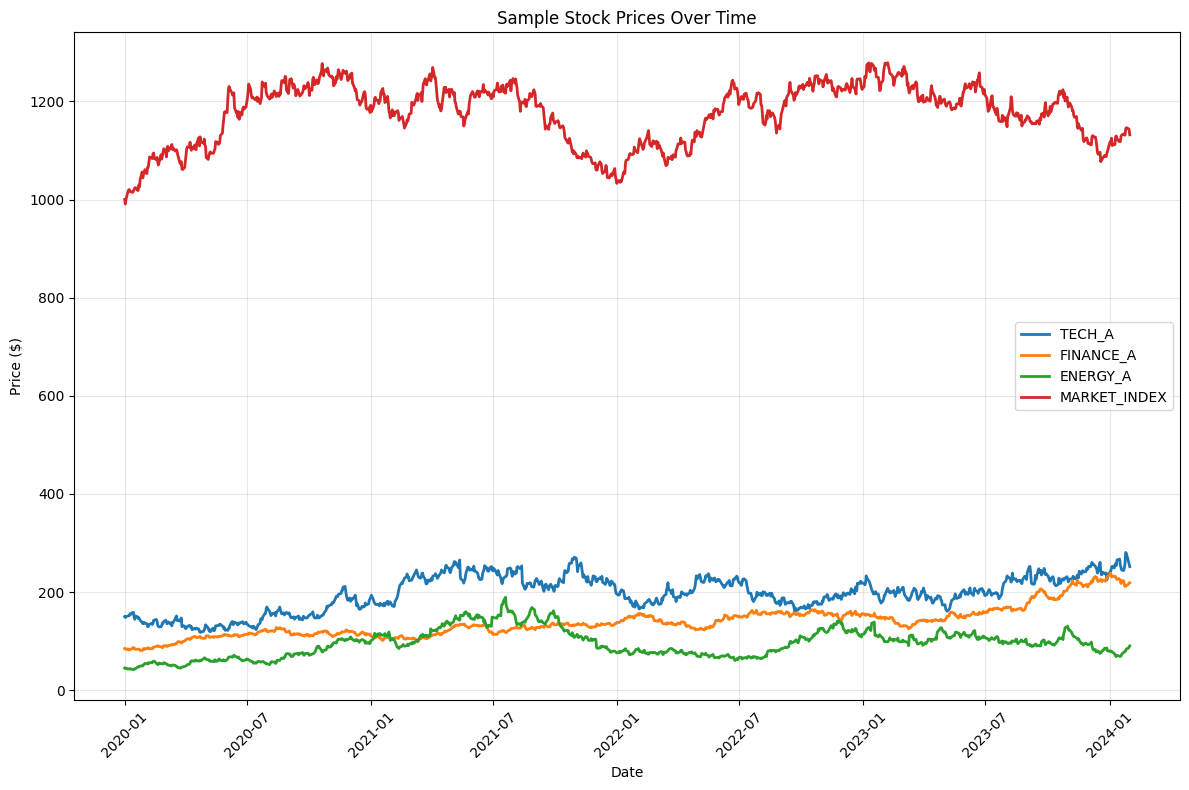

Sample visualization created: 'sample_stock_prices.png'

DATASET GENERATION COMPLETE!
Files created:
1. comprehensive_stock_dataset.csv - Main dataset
2. dataset_summary.csv - Summary statistics
3. sample_stock_prices.png - Sample visualization

The dataset is ready for your Streamlit dashboard!


In [1]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import random

class StockDataGenerator:
    def __init__(self, start_date='2020-01-01', end_date='2024-01-31'):
        self.start_date = start_date
        self.end_date = end_date
        self.date_range = pd.date_range(start=start_date, end=end_date, freq='B')  # Business days only
        
    def generate_company_profile(self, company_type):
        """Define different company characteristics based on sector"""
        profiles = {
            'tech_growth': {
                'base_volatility': 0.025,
                'trend_strength': 0.0008,
                'event_probability': 0.03,
                'volume_base': 10000000
            },
            'tech_established': {
                'base_volatility': 0.018,
                'trend_strength': 0.0005,
                'event_probability': 0.02,
                'volume_base': 25000000
            },
            'finance': {
                'base_volatility': 0.015,
                'trend_strength': 0.0003,
                'event_probability': 0.015,
                'volume_base': 15000000
            },
            'healthcare': {
                'base_volatility': 0.022,
                'trend_strength': 0.0006,
                'event_probability': 0.025,
                'volume_base': 8000000
            },
            'energy': {
                'base_volatility': 0.028,
                'trend_strength': 0.0002,
                'event_probability': 0.035,
                'volume_base': 12000000
            },
            'consumer': {
                'base_volatility': 0.012,
                'trend_strength': 0.0004,
                'event_probability': 0.01,
                'volume_base': 18000000
            }
        }
        return profiles.get(company_type, profiles['tech_established'])
    
    def generate_stock_data(self, ticker, company_type, initial_price):
        """Generate realistic stock data for one company"""
        profile = self.generate_company_profile(company_type)
        n_days = len(self.date_range)
        
        # Initialize arrays
        close_prices = [initial_price]
        volumes = [profile['volume_base'] * random.uniform(0.8, 1.2)]
        
        # Generate price series with trends, volatility, and events
        for day in range(1, n_days):
            # Base return with trend
            base_return = np.random.normal(profile['trend_strength'], profile['base_volatility'])
            
            # Add market events (big moves)
            if random.random() < profile['event_probability']:
                event_impact = np.random.normal(0, profile['base_volatility'] * 3)
                base_return += event_impact
            
            # Add some autocorrelation (momentum effects)
            if day > 1:
                prev_return = (close_prices[-1] - close_prices[-2]) / close_prices[-2]
                momentum_effect = prev_return * 0.1 * random.random()
                base_return += momentum_effect
            
            # Calculate new price
            new_price = close_prices[-1] * (1 + base_return)
            close_prices.append(new_price)
            
            # Generate volume with some correlation to price movement
            volume_change = abs(base_return) * 5000000 * random.uniform(0.5, 2)
            new_volume = max(1000000, volumes[-1] * random.uniform(0.7, 1.3) + volume_change)
            volumes.append(int(new_volume))
        
        # Create DataFrame with OHLC data
        df = pd.DataFrame({
            'Date': self.date_range,
            'Ticker': ticker,
            'Sector': company_type,
            'Close': close_prices
        })
        
        # Generate OHLC from close prices with realistic patterns
        df['Open'] = df['Close'].shift(1) * (1 + np.random.normal(0, 0.003, n_days))
        df['High'] = df[['Open', 'Close']].max(axis=1) * (1 + np.abs(np.random.normal(0, 0.008, n_days)))
        df['Low'] = df[['Open', 'Close']].min(axis=1) * (1 - np.abs(np.random.normal(0, 0.008, n_days)))
        df['Volume'] = volumes
        df['Adj Close'] = df['Close']  # For simplicity in synthetic data
        
        # Handle first row
        df.loc[0, 'Open'] = df.loc[0, 'Close'] * random.uniform(0.98, 1.0)
        df.loc[0, 'High'] = max(df.loc[0, 'Open'], df.loc[0, 'Close']) * random.uniform(1.0, 1.02)
        df.loc[0, 'Low'] = min(df.loc[0, 'Open'], df.loc[0, 'Close']) * random.uniform(0.98, 1.0)
        
        # Add some market cap information for context
        df['Market_Cap'] = df['Close'] * (profile['volume_base'] / 100) * random.uniform(0.8, 1.2)
        
        return df.dropna()
    
    def generate_market_index(self):
        """Generate a market index (like S&P 500) for comparison"""
        n_days = len(self.date_range)
        index_values = [1000]  # Start at 1000 points
        
        for day in range(1, n_days):
            # Market index is less volatile than individual stocks
            daily_return = np.random.normal(0.0004, 0.008)
            
            # Add some market cycles
            cycle_effect = 0.0001 * np.sin(day / 30)  # Roughly monthly cycles
            daily_return += cycle_effect
            
            new_value = index_values[-1] * (1 + daily_return)
            index_values.append(new_value)
        
        market_df = pd.DataFrame({
            'Date': self.date_range,
            'Ticker': 'MARKET_INDEX',
            'Sector': 'Index',
            'Close': index_values,
            'Open': [index_values[i] * random.uniform(0.995, 1.0) for i in range(n_days)],
            'High': [index_values[i] * random.uniform(1.0, 1.01) for i in range(n_days)],
            'Low': [index_values[i] * random.uniform(0.99, 1.0) for i in range(n_days)],
            'Volume': [int(1e9 * random.uniform(0.8, 1.2)) for _ in range(n_days)],
            'Adj Close': index_values,
            'Market_Cap': [1e12] * n_days
        })
        
        return market_df
    
    def generate_complete_dataset(self):
        """Generate dataset for multiple companies"""
        companies = [
            ('TECH_A', 'tech_growth', 150),
            ('TECH_B', 'tech_established', 280),
            ('FINANCE_A', 'finance', 85),
            ('HEALTH_A', 'healthcare', 120),
            ('ENERGY_A', 'energy', 45),
            ('CONSUMER_A', 'consumer', 65),
            ('TECH_C', 'tech_growth', 320),
            ('FINANCE_B', 'finance', 110)
        ]
        
        all_data = []
        
        # Generate market index first
        market_data = self.generate_market_index()
        all_data.append(market_data)
        
        # Generate individual stocks
        for ticker, sector, initial_price in companies:
            print(f"Generating data for {ticker}...")
            stock_data = self.generate_stock_data(ticker, sector, initial_price)
            all_data.append(stock_data)
        
        # Combine all data
        complete_dataset = pd.concat(all_data, ignore_index=True)
        
        # Add some additional calculated fields
        complete_dataset['Daily_Return'] = complete_dataset.groupby('Ticker')['Close'].pct_change()
        complete_dataset['Price_Change'] = complete_dataset.groupby('Ticker')['Close'].diff()
        
        return complete_dataset

# Generate and save the dataset
def create_and_save_dataset():
    print("Starting synthetic stock data generation...")
    generator = StockDataGenerator()
    
    # Generate complete dataset
    dataset = generator.generate_complete_dataset()
    
    # Save to CSV
    dataset.to_csv('comprehensive_stock_dataset.csv', index=False)
    
    # Also create a summary statistics file
    summary = dataset.groupby('Ticker').agg({
        'Close': ['mean', 'std', 'min', 'max'],
        'Volume': 'mean',
        'Daily_Return': 'std'
    }).round(2)
    
    summary.to_csv('dataset_summary.csv')
    
    print("Dataset generation completed!")
    print(f"Dataset shape: {dataset.shape}")
    print(f"Date range: {dataset['Date'].min()} to {dataset['Date'].max()}")
    print(f"Companies generated: {dataset['Ticker'].unique().tolist()}")
    print(f"Sectors: {dataset['Sector'].unique().tolist()}")
    
    # Display sample data
    print("\nSample of the dataset:")
    print(dataset.head(10))
    
    return dataset

# Additional function to create sample visualizations
def create_sample_visualization(dataset):
    """Create a simple sample visualization to verify data quality"""
    import matplotlib.pyplot as plt
    
    # Plot a few stocks
    plt.figure(figsize=(12, 8))
    
    stocks_to_plot = ['TECH_A', 'FINANCE_A', 'ENERGY_A', 'MARKET_INDEX']
    
    for ticker in stocks_to_plot:
        stock_data = dataset[dataset['Ticker'] == ticker]
        plt.plot(stock_data['Date'], stock_data['Close'], label=ticker, linewidth=2)
    
    plt.title('Sample Stock Prices Over Time')
    plt.xlabel('Date')
    plt.ylabel('Price ($)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig('sample_stock_prices.png', dpi=300, bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    # Generate the dataset
    stock_dataset = create_and_save_dataset()
    
    # Create a visualization sample
    try:
        create_sample_visualization(stock_dataset)
        print("Sample visualization created: 'sample_stock_prices.png'")
    except Exception as e:
        print(f"Visualization skipped: {e}")
    
    print("\n" + "="*50)
    print("DATASET GENERATION COMPLETE!")
    print("="*50)
    print("Files created:")
    print("1. comprehensive_stock_dataset.csv - Main dataset")
    print("2. dataset_summary.csv - Summary statistics")
    print("3. sample_stock_prices.png - Sample visualization")
    print("\nThe dataset is ready for your Streamlit dashboard!")